# Evaluation of Spectral Index-Based Binary Masks

This notebook evaluates binary water masks generated from spectral indices (NDWI, MNDWI, AWEInsh, AWEIsh, SCOWI) against ground truth annotations.

## Evaluation Strategy

- For each ground truth image and binary mask combination (index × threshold)
- Collapse GT multi-class to binary water/no-water (with ignore mask)
- Crop both GT and prediction to each patch geometry
- Calculate IoU and Dice metrics excluding ignore pixels
- Aggregate results into a DataFrame for analysis

## Class Mapping

Based on the ground truth annotation masks:

- **Water**: classes 3 (water) + 5 (white_water)
- **No-water**: classes 2 (sand) + 4 (wet_sand)  
- **Ignore**: classes 1 (clouds) + 255 (unannotated background)

## Metrics

- **IoU (Intersection over Union)**: Measures overlap between prediction and ground truth
- **Dice Coefficient**: Harmonic mean of precision and recall
- Both metrics exclude pixels marked as "ignore"

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rasterio_mask
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import Tuple, Optional, Dict, List
import warnings
warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)

# Add src to path for any future imports if needed
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Libraries imported successfully!")

c:\Users\usuari\anaconda3\envs\s2_benchmarking\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Libraries imported successfully!


## Configuration

Define paths, study areas, and class mappings for the evaluation.

In [3]:
# Study areas
STUDY_NAMES = ["puntal", "salinas"]

# Base directories (relative to notebook location)
BASE_DIR = Path("..") / "data"
IMAGES_DIR = BASE_DIR / "images"
PATCHES_DIR = BASE_DIR / "coastal_rois_for_patches"

# Class mapping for GT masks
GT_CLASS_MAPPING = {
    'water_classes': [3, 5],      # water, white_water
    'no_water_classes': [2, 4],   # sand, wet_sand
    'ignore_classes': [1, 255]    # clouds, unannotated
}

# Spectral indices and thresholding methods
INDICES = ['ndwi', 'mndwi', 'aweinsh', 'aweish', 'scowi']
THRESHOLDS = ['zero', 'otsu', 'otsu_modified']

# Patch size
PATCH_SIZE = "128_128"

# Boundary zone evaluation parameters
BOUNDARY_OFFSET_PIXELS = 10  # Symmetric offset around water/land boundary
MIN_BOUNDARY_PIXELS = 50     # Minimum pixels required in boundary zone to evaluate patch

# Configure geopandas to use fiona engine instead of pyogrio (more stable)
import geopandas as gpd
gpd.options.io_engine = "fiona"

print("Configuration loaded successfully!")
print(f"Study areas: {STUDY_NAMES}")
print(f"Indices: {INDICES}")
print(f"Thresholds: {THRESHOLDS}")
print(f"Boundary offset: {BOUNDARY_OFFSET_PIXELS} pixels")
print(f"Minimum boundary pixels: {MIN_BOUNDARY_PIXELS}")
print(f"GeoPandas engine: {gpd.options.io_engine}")

Configuration loaded successfully!
Study areas: ['puntal', 'salinas']
Indices: ['ndwi', 'mndwi', 'aweinsh', 'aweish', 'scowi']
Thresholds: ['zero', 'otsu', 'otsu_modified']
Boundary offset: 10 pixels
Minimum boundary pixels: 50
GeoPandas engine: fiona


## Helper Functions

Functions for processing ground truth masks, cropping rasters, and calculating metrics.

In [4]:
def collapse_gt_to_binary(
    gt_array: np.ndarray,
    water_classes: List[int] = [3, 5],
    no_water_classes: List[int] = [2, 4],
    ignore_classes: List[int] = [1, 255]
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Collapse multi-class GT mask to binary water/no-water with ignore mask.
    
    Parameters
    ----------
    gt_array : np.ndarray
        Multi-class ground truth array
    water_classes : List[int]
        Pixel values representing water
    no_water_classes : List[int]
        Pixel values representing no-water (land)
    ignore_classes : List[int]
        Pixel values to ignore in evaluation
        
    Returns
    -------
    binary_gt : np.ndarray (uint8)
        Binary mask where 1=water, 0=no-water
    ignore_mask : np.ndarray (bool)
        True for pixels that should be ignored
        
    Notes
    -----
    - Pixels with ignore_classes are marked in ignore_mask
    - Pixels NOT in any known class (water, no-water, ignore) are also marked as ignore
    - This prevents creating artificial boundaries with unannotated regions
    - Binary GT only contains valid 0/1 values for explicitly annotated pixels
    """
    binary_gt = np.zeros_like(gt_array, dtype=np.uint8)
    
    # All known/valid classes
    all_known_classes = water_classes + no_water_classes + ignore_classes
    
    # Create ignore mask for:
    # 1. Explicit ignore classes (clouds=1, unannotated background=255)
    # 2. Any pixel NOT in water, no-water, or ignore classes (unannotated pixels like value 0)
    ignore_mask = ~np.isin(gt_array, all_known_classes) | np.isin(gt_array, ignore_classes)
    
    # Mark water pixels as 1
    binary_gt[np.isin(gt_array, water_classes)] = 1
    # No-water pixels remain 0 (only if explicitly in no_water_classes)
    
    return binary_gt, ignore_mask

print("Function 'collapse_gt_to_binary' defined successfully!")

Function 'collapse_gt_to_binary' defined successfully!


In [5]:
def create_boundary_zone_mask(
    binary_mask: np.ndarray,
    ignore_mask: np.ndarray,
    offset_pixels: int
) -> np.ndarray:
    """
    Create a symmetric buffer zone around the water/land boundary.
    Only considers explicitly annotated pixels (excludes ignored/unannotated pixels).

    Uses Euclidean Distance Transform (EDT) to identify pixels within
    a specified distance from both water and land classes.

    Parameters
    ----------
    binary_mask : np.ndarray (uint8)
        Binary mask where 1=water, 0=land
    ignore_mask : np.ndarray (bool)
        Mask of pixels to ignore (True = ignore, False = valid)
    offset_pixels : int
        Number of pixels to extend buffer on each side of boundary

    Returns
    -------
    boundary_zone : np.ndarray (bool)
        Boolean mask where True=inside boundary zone, False=outside
        Returns all False if no boundary exists (all water, all land, or insufficient valid pixels)

    Notes
    -----
    - Creates symmetric buffer (equal distance landward and seaward)
    - Uses distance_transform_edt for Euclidean distance (circular buffer)
    - Only valid (non-ignored) pixels are used to compute boundaries
    - This prevents artificial boundaries at edges of unannotated regions
    - Consistent with existing codebase (masks_from_coco.py uses EDT)

    Examples
    --------
    >>> binary_gt = np.array([[0, 0, 1, 1], [0, 0, 1, 1]])
    >>> ignore_mask = np.zeros_like(binary_gt, dtype=bool)
    >>> boundary = create_boundary_zone_mask(binary_gt, ignore_mask, offset_pixels=1)
    >>> # Returns zone within 1 pixel of water/land boundary
    """
    from scipy.ndimage import distance_transform_edt

    # Create masks for valid water and valid land only
    valid_mask = ~ignore_mask
    water_valid = (binary_mask == 1) & valid_mask
    land_valid = (binary_mask == 0) & valid_mask

    # Handle edge case: no valid boundary exists
    if not (np.any(water_valid) and np.any(land_valid)):
        return np.zeros_like(binary_mask, dtype=bool)

    # Compute distance from valid water pixels
    # EDT of ~water_valid gives distance to nearest valid water pixel
    dist_from_water = distance_transform_edt(~water_valid)

    # Compute distance from valid land pixels
    # EDT of ~land_valid gives distance to nearest valid land pixel
    dist_from_land = distance_transform_edt(~land_valid)

    # Boundary zone = valid pixels within offset distance from BOTH water AND land
    # This ensures we only get boundaries between explicitly annotated water and land
    boundary_zone = (dist_from_water <= offset_pixels) & (dist_from_land <= offset_pixels) & valid_mask

    return boundary_zone

print("Function 'create_boundary_zone_mask' defined successfully!")

Function 'create_boundary_zone_mask' defined successfully!


In [6]:
def crop_raster_by_geometry(
    raster_path: Path,
    geometry,
    nodata: Optional[int] = None
) -> Tuple[Optional[np.ndarray], Optional[rasterio.Affine], bool]:
    """
    Crop a raster file to a polygon geometry.
    
    Parameters
    ----------
    raster_path : Path
        Path to raster file
    geometry : shapely.geometry.Polygon
        Polygon to crop to
    nodata : Optional[int]
        NoData value to use
        
    Returns
    -------
    cropped_array : np.ndarray or None
        Cropped raster array (2D), None if empty intersection
    transform : rasterio.Affine or None
        Affine transform of cropped raster, None if empty
    is_empty : bool
        True if intersection is empty or all pixels are nodata
        
    Notes
    -----
    - Returns None arrays if polygon doesn't intersect raster
    - Handles cases where crop results in all-nodata array
    """
    try:
        with rasterio.open(raster_path) as src:
            # Crop to geometry
            cropped, transform = rasterio_mask(
                src, 
                [geometry], 
                crop=True,
                filled=True,
                nodata=nodata if nodata is not None else 0
            )
            
            # Extract first band (should be single-band)
            cropped_array = cropped[0]
            
            # Check if crop is empty or all nodata
            if cropped_array.size == 0:
                return None, None, True
                
            # Check if all pixels are nodata
            if nodata is not None and np.all(cropped_array == nodata):
                return None, None, True
                
            return cropped_array, transform, False
            
    except Exception as e:
        print(f"Warning: Failed to crop {raster_path.name}: {e}")
        return None, None, True

print("Function 'crop_raster_by_geometry' defined successfully!")

Function 'crop_raster_by_geometry' defined successfully!


In [7]:
def calculate_metrics(
    gt_binary: np.ndarray,
    pred_binary: np.ndarray,
    ignore_mask: np.ndarray
) -> Dict[str, float]:
    """
    Calculate IoU and Dice coefficient, excluding ignored pixels.
    
    Parameters
    ----------
    gt_binary : np.ndarray
        Ground truth binary mask (0/1)
    pred_binary : np.ndarray
        Predicted binary mask (0/1)
    ignore_mask : np.ndarray (bool)
        Mask of pixels to ignore (True = ignore)
        
    Returns
    -------
    metrics : Dict[str, float]
        Dictionary with 'iou', 'dice', and 'valid_pixel_count'
        Returns NaN values if no valid pixels exist
        
    Notes
    -----
    - IoU = Intersection / Union
    - Dice = 2 * Intersection / (|A| + |B|)
    - Both metrics exclude pixels where ignore_mask is True
    """
    # Create valid pixel mask (not ignored)
    valid_mask = ~ignore_mask
    
    # Count valid pixels
    valid_pixel_count = np.sum(valid_mask)
    
    # If no valid pixels, return NaN
    if valid_pixel_count == 0:
        return {
            'iou': np.nan,
            'dice': np.nan,
            'valid_pixel_count': 0
        }
    
    # Apply valid mask to both arrays
    gt_valid = gt_binary[valid_mask]
    pred_valid = pred_binary[valid_mask]
    
    # Calculate intersection and union
    intersection = np.sum((gt_valid == 1) & (pred_valid == 1))
    union = np.sum((gt_valid == 1) | (pred_valid == 1))
    
    # Calculate IoU
    iou = intersection / union if union > 0 else 0.0
    
    # Calculate Dice
    gt_sum = np.sum(gt_valid == 1)
    pred_sum = np.sum(pred_valid == 1)
    dice = (2 * intersection) / (gt_sum + pred_sum) if (gt_sum + pred_sum) > 0 else 0.0
    
    return {
        'iou': float(iou),
        'dice': float(dice),
        'valid_pixel_count': int(valid_pixel_count)
    }

print("Function 'calculate_metrics' defined successfully!")

Function 'calculate_metrics' defined successfully!


In [8]:
def get_binary_mask_path(
    gt_filename: str,
    study_name: str,
    index: str,
    threshold: str
) -> Path:
    """
    Construct binary mask path from GT filename, index, and threshold.
    
    Parameters
    ----------
    gt_filename : str
        GT mask filename, e.g., '2016-06-26-11-12-58_S2_30TVP_PUNTAL_mask_gt.tif'
    study_name : str
        Study area name ('puntal' or 'salinas')
    index : str
        Spectral index name ('ndwi', 'mndwi', 'aweinsh', 'scowi')
    threshold : str
        Threshold method ('zero', 'otsu', 'otsu_modified')
        
    Returns
    -------
    mask_path : Path
        Path to binary mask file
        
    Notes
    -----
    GT filename format:    YYYY-MM-DD-HH-MM-SS_S2_{tile}_{SITE}_mask_gt.tif
    Binary mask format:    YYYY-MM-DD-HH-MM-SS_S2_{tile}_{SITE}_{index}_mask_{threshold}.tif
    """
    # Remove '_mask_gt.tif' suffix
    base_name = gt_filename.replace('_mask_gt.tif', '')
    
    # Construct binary mask filename
    mask_filename = f"{base_name}_{index}_mask_{threshold}.tif"
    
    # Construct full path
    mask_path = IMAGES_DIR / study_name / "binary_masks" / mask_filename
    
    return mask_path

print("Function 'get_binary_mask_path' defined successfully!")

Function 'get_binary_mask_path' defined successfully!


In [9]:
def parse_gt_filename(filename: str) -> Dict[str, str]:
    """
    Extract metadata from GT filename.
    
    Parameters
    ----------
    filename : str
        GT filename, e.g., '2016-06-26-11-12-58_S2_30TVP_PUNTAL_mask_gt.tif'
        
    Returns
    -------
    metadata : Dict[str, str]
        Dictionary with 'date', 'time', 'tile', 'site'
        
    Notes
    -----
    Format: YYYY-MM-DD-HH-MM-SS_S2_{tile}_{SITE}_mask_gt.tif
    """
    # Remove extension and suffix
    name = filename.replace('_mask_gt.tif', '')
    
    # Split by underscore
    parts = name.split('_')
    
    # Extract date and time
    datetime_parts = parts[0].split('-')
    date = f"{datetime_parts[0]}-{datetime_parts[1]}-{datetime_parts[2]}"
    time = f"{datetime_parts[3]}:{datetime_parts[4]}:{datetime_parts[5]}"
    
    # Extract tile and site
    tile = parts[2] if len(parts) > 2 else "unknown"
    site = parts[3].upper() if len(parts) > 3 else "unknown"
    
    return {
        'date': date,
        'time': time,
        'tile': tile,
        'site': site
    }

print("Function 'parse_gt_filename' defined successfully!")

Function 'parse_gt_filename' defined successfully!


## Main Evaluation Loop

Iterate through all GT images, binary masks, and patches to compute metrics.

In [10]:
def evaluate_all_masks() -> pd.DataFrame:
    """
    Evaluate all binary masks against ground truth for all patches.
    
    Returns
    -------
    results_df : pd.DataFrame
        DataFrame with columns:
        - study_name: str
        - date: str (YYYY-MM-DD)
        - time: str (HH:MM:SS)
        - tile: str (Sentinel-2 tile ID)
        - site: str (PUNTAL or SALINAS)
        - patch_id: int (FID from shapefile)
        - index: str (ndwi, mndwi, aweinsh, aweish, scowi)
        - threshold: str (zero, otsu, otsu_modified)
        - iou: float
        - dice: float
        - boundary_pixel_count: int
        - boundary_offset_pixels: int
        
    Notes
    -----
    - Skips combinations where binary mask file doesn't exist
    - Skips patches with empty intersections
    - Skips patches with insufficient boundary pixels
    - Evaluates only pixels within boundary zone
    - Prints progress messages during execution
    """
    results = []
    
    for study_name in STUDY_NAMES:
        print(f"\n{'='*60}")
        print(f"Processing study area: {study_name.upper()}")
        print(f"{'='*60}")
        
        # Define paths
        gt_dir = IMAGES_DIR / study_name / "annotation_masks_gt"
        patches_path = PATCHES_DIR / study_name / f"roi_{study_name}_{PATCH_SIZE}_patches.shp"
        
        # Check if paths exist
        if not gt_dir.exists():
            print(f"Warning: GT directory not found: {gt_dir}")
            continue
            
        if not patches_path.exists():
            print(f"Warning: Patches file not found: {patches_path}")
            continue
        
        # Load patches - try multiple engines
        try:
            # Try with fiona first
            patches_gdf = gpd.read_file(patches_path, engine='fiona')
            print(f"Loaded {len(patches_gdf)} patches from {patches_path.name}")
        except Exception as e1:
            try:
                # Try reading without specifying engine and ignore CRS validation
                import fiona
                fiona.drvsupport.supported_drivers['ESRI Shapefile'] = 'rw'
                
                # Read directly with fiona
                with fiona.open(patches_path) as src:
                    geometries = []
                    for feature in src:
                        from shapely.geometry import shape
                        geometries.append(shape(feature['geometry']))
                
                patches_gdf = gpd.GeoDataFrame({'geometry': geometries})
                patches_gdf.crs = None  # Ignore CRS for now
                print(f"Loaded {len(patches_gdf)} patches from {patches_path.name} (using fiona directly)")
                
            except Exception as e2:
                print(f"Error loading patches with fiona: {e1}")
                print(f"Error loading patches with direct fiona: {e2}")
                continue
        
        # Get list of GT files
        gt_files = sorted([f for f in os.listdir(gt_dir) if f.endswith('_mask_gt.tif')])
        print(f"Found {len(gt_files)} ground truth masks")
        
        # Iterate over GT files
        for gt_idx, gt_filename in enumerate(gt_files, 1):
            print(f"\n[{gt_idx}/{len(gt_files)}] Processing: {gt_filename}")
            
            # Parse metadata
            metadata = parse_gt_filename(gt_filename)
            
            # GT path
            gt_path = gt_dir / gt_filename
            
            # Iterate over indices and thresholds
            for index in INDICES:
                for threshold in THRESHOLDS:
                    # Get binary mask path
                    binary_mask_path = get_binary_mask_path(
                        gt_filename, study_name, index, threshold
                    )
                    
                    # Check if binary mask exists
                    if not binary_mask_path.exists():
                        # print(f"  Warning: Binary mask not found: {binary_mask_path.name}")
                        continue
                    
                    # Iterate over patches
                    for patch_idx, patch_row in patches_gdf.iterrows():
                        patch_geom = patch_row.geometry
                        patch_id = int(patch_idx)  # Use index as patch_id
                        
                        # Crop GT mask to patch
                        gt_cropped, gt_transform, gt_empty = crop_raster_by_geometry(
                            gt_path, patch_geom, nodata=None
                        )
                        
                        if gt_empty or gt_cropped is None:
                            # Skip if no intersection
                            continue
                        
                        # Crop binary mask to patch
                        pred_cropped, pred_transform, pred_empty = crop_raster_by_geometry(
                            binary_mask_path, patch_geom, nodata=0
                        )
                        
                        if pred_empty or pred_cropped is None:
                            # Skip if no intersection
                            continue
                        
                        # Check shape consistency
                        if gt_cropped.shape != pred_cropped.shape:
                            print(f"  Warning: Shape mismatch for patch {patch_id}, "
                                  f"index {index}, threshold {threshold}")
                            continue
                        
                        # Collapse GT to binary
                        gt_binary, ignore_mask = collapse_gt_to_binary(
                            gt_cropped,
                            water_classes=GT_CLASS_MAPPING['water_classes'],
                            no_water_classes=GT_CLASS_MAPPING['no_water_classes'],
                            ignore_classes=GT_CLASS_MAPPING['ignore_classes']
                        )
                        
                        # Create boundary zone mask (now with ignore_mask parameter)
                        boundary_zone = create_boundary_zone_mask(
                            gt_binary,
                            ignore_mask,
                            offset_pixels=BOUNDARY_OFFSET_PIXELS
                        )
                        
                        # Combine boundary zone with ignore mask
                        # Evaluation mask = pixels that are:
                        #   - Inside boundary zone (boundary_zone == True)
                        #   - NOT ignored (ignore_mask == False)
                        evaluation_mask = boundary_zone & (~ignore_mask)
                        
                        # Convert to "ignore" format expected by calculate_metrics()
                        combined_ignore_mask = ~evaluation_mask
                        
                        # Check if boundary zone has sufficient pixels
                        boundary_pixel_count = np.sum(evaluation_mask)
                        if boundary_pixel_count < MIN_BOUNDARY_PIXELS:
                            continue  # Skip patch - insufficient boundary pixels
                        
                        # Calculate metrics (now only on boundary zone)
                        metrics = calculate_metrics(gt_binary, pred_cropped, combined_ignore_mask)
                        
                        # Skip if calculation failed (shouldn't happen if boundary_pixel_count > 0)
                        if metrics['valid_pixel_count'] == 0:
                            continue
                        
                        # Store result
                        results.append({
                            'study_name': study_name,
                            'date': metadata['date'],
                            'time': metadata['time'],
                            'tile': metadata['tile'],
                            'site': metadata['site'],
                            'patch_id': patch_id,
                            'index': index,
                            'threshold': threshold,
                            'iou': metrics['iou'],
                            'dice': metrics['dice'],
                            'boundary_pixel_count': int(boundary_pixel_count),
                            'boundary_offset_pixels': BOUNDARY_OFFSET_PIXELS,
                        })
            
            # Print progress after each GT file
            results_for_this_gt = [r for r in results 
                                   if r['date'] == metadata['date'] and r['time'] == metadata['time']]
            print(f"  Completed: {len(results_for_this_gt)} valid patch evaluations")
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    print(f"\n{'='*60}")
    print(f"Evaluation complete!")
    print(f"Total results: {len(results_df)}")
    print(f"{'='*60}")
    
    return results_df

print("Function 'evaluate_all_masks' defined successfully!")

Function 'evaluate_all_masks' defined successfully!


In [11]:
# Run the evaluation
results_df = evaluate_all_masks()

# Display first few rows
print("\nFirst 10 results:")
display(results_df.head(10))


Processing study area: PUNTAL
Loaded 4 patches from roi_puntal_128_128_patches.shp (using fiona directly)
Found 12 ground truth masks

[1/12] Processing: 2016-06-26-11-12-58_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[2/12] Processing: 2016-07-16-11-19-09_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[3/12] Processing: 2017-04-12-11-19-04_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[4/12] Processing: 2017-10-14-11-17-16_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[5/12] Processing: 2018-04-17-11-08-22_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[6/12] Processing: 2018-11-18-11-19-02_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[7/12] Processing: 2019-03-23-11-19-04_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations

[8/12] Processing: 2019-03-28-11-19-07_S2_30TVP_PUNTAL_mask_gt.tif
  Completed: 48 valid patch evaluations



,study_name,date,time,tile,site,patch_id,index,threshold,iou,dice,boundary_pixel_count,boundary_offset_pixels
0,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,0,ndwi,zero,0.936324,0.967115,2353,10
1,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,1,ndwi,zero,0.944404,0.971407,2586,10
2,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,2,ndwi,zero,0.928702,0.963033,3050,10
3,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,3,ndwi,zero,0.929917,0.963686,2458,10
4,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,0,ndwi,otsu,0.936324,0.967115,2353,10
5,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,1,ndwi,otsu,0.944404,0.971407,2586,10
6,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,2,ndwi,otsu,0.928136,0.962729,3050,10
7,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,3,ndwi,otsu,0.929217,0.963310,2458,10
8,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,0,ndwi,otsu_modified,0.940407,0.969288,2353,10
9,puntal,2016-06-26,11:12:58,30TVP,PUNTAL,1,ndwi,otsu_modified,0.948567,0.973605,2586,10


## Results Summary

Basic statistics and overview of evaluation results.

In [12]:
# Display dataset info
print("Dataset Overview:")
print(f"Total evaluations: {len(results_df)}")

if len(results_df) > 0:
    print(f"Study areas: {results_df['study_name'].unique()}")
    print(f"Unique dates: {results_df['date'].nunique()}")
    print(f"Indices: {results_df['index'].unique()}")
    print(f"Thresholds: {results_df['threshold'].unique()}")
    print(f"Boundary offset used: {results_df['boundary_offset_pixels'].iloc[0]} pixels")
    print(f"Mean boundary pixels/patch: {results_df['boundary_pixel_count'].mean():.1f}")

    # Summary statistics by index
    print("\n" + "="*60)
    print("Mean IoU by Index:")
    print("="*60)
    print(results_df.groupby('index')['iou'].mean().sort_values(ascending=False))

    print("\n" + "="*60)
    print("Mean Dice by Index:")
    print("="*60)
    print(results_df.groupby('index')['dice'].mean().sort_values(ascending=False))

    # Summary by threshold
    print("\n" + "="*60)
    print("Mean IoU by Threshold:")
    print("="*60)
    print(results_df.groupby('threshold')['iou'].mean().sort_values(ascending=False))

    # Summary by study area
    print("\n" + "="*60)
    print("Mean IoU by Study Area:")
    print("="*60)
    print(results_df.groupby('study_name')['iou'].mean())
else:
    print("\nNo results to display. Check if binary masks exist and patches can be loaded.")

Dataset Overview:
Total evaluations: 1464
Study areas: <StringArray>
['puntal', 'salinas']
Length: 2, dtype: str
Unique dates: 48
Indices: <StringArray>
['ndwi', 'mndwi', 'aweinsh', 'scowi']
Length: 4, dtype: str
Thresholds: <StringArray>
['zero', 'otsu', 'otsu_modified']
Length: 3, dtype: str
Boundary offset used: 10 pixels
Mean boundary pixels/patch: 2294.8

Mean IoU by Index:
index
ndwi       0.805203
mndwi      0.767715
aweinsh    0.761621
scowi      0.751143
Name: iou, dtype: float64

Mean Dice by Index:
index
ndwi       0.879297
mndwi      0.859407
aweinsh    0.854860
scowi      0.845191
Name: dice, dtype: float64

Mean IoU by Threshold:
threshold
zero             0.779804
otsu_modified    0.769303
otsu             0.765155
Name: iou, dtype: float64

Mean IoU by Study Area:
study_name
puntal     0.873311
salinas    0.705329
Name: iou, dtype: float64


In [13]:
# Save results to CSV
output_path = Path("..") / "results" / "pixel_based_metrics_results.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)
print(f"Results saved to: {output_path}")

Results saved to: ..\results\pixel_based_metrics_results.csv


## Visualization

Basic plots to visualize performance across different indices and thresholds.


Figure saved to: ..\results\evaluation_overview_puntal.png


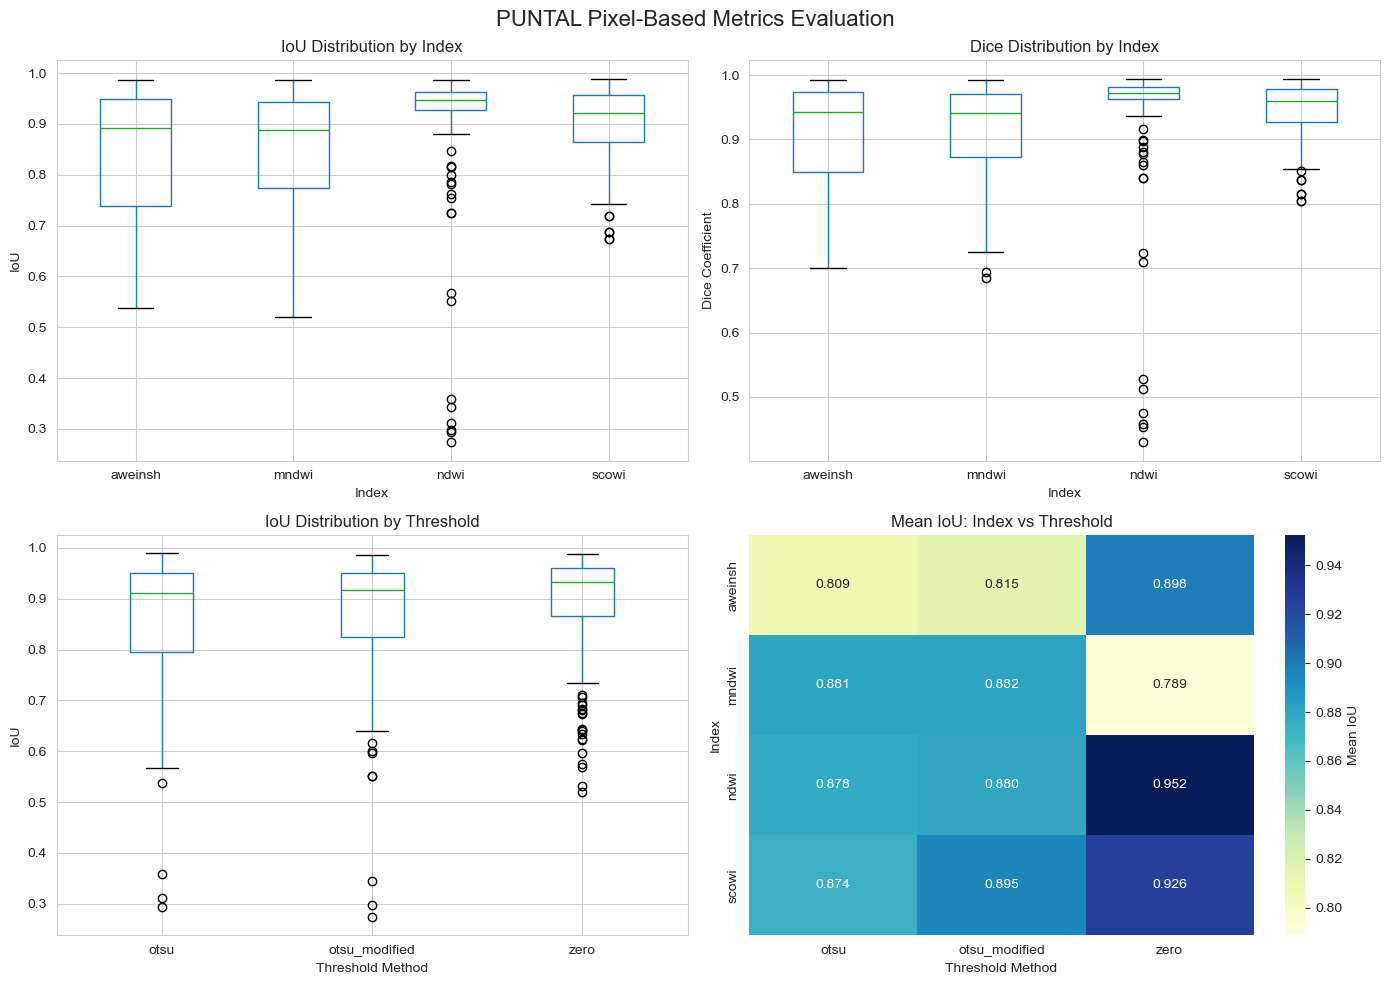


Figure saved to: ..\results\evaluation_overview_salinas.png


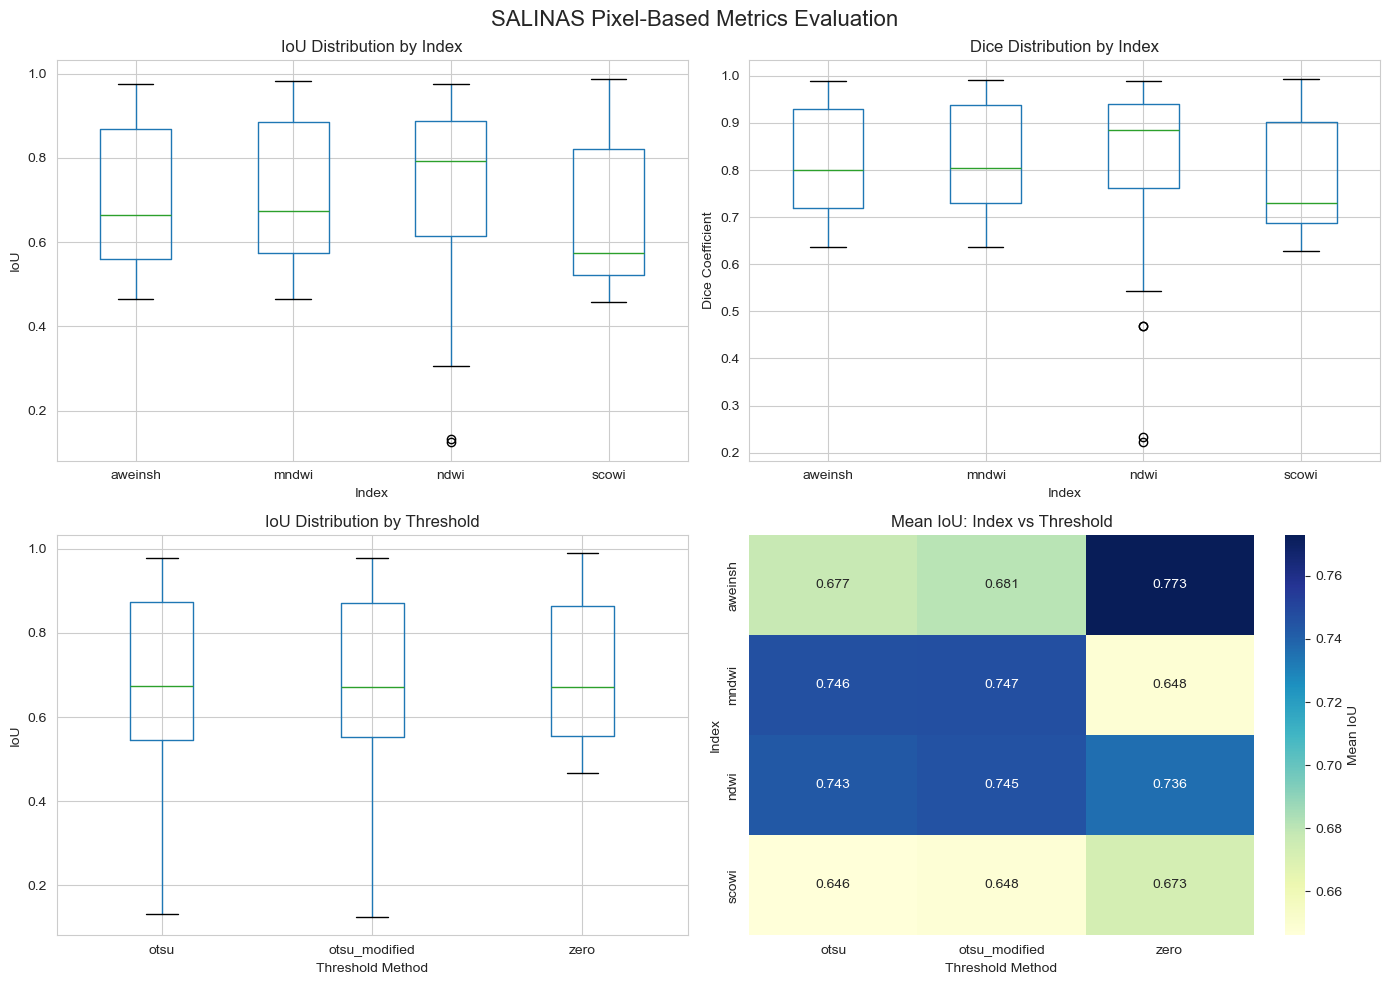


Figure saved to: ..\results\evaluation_overview_overall.png


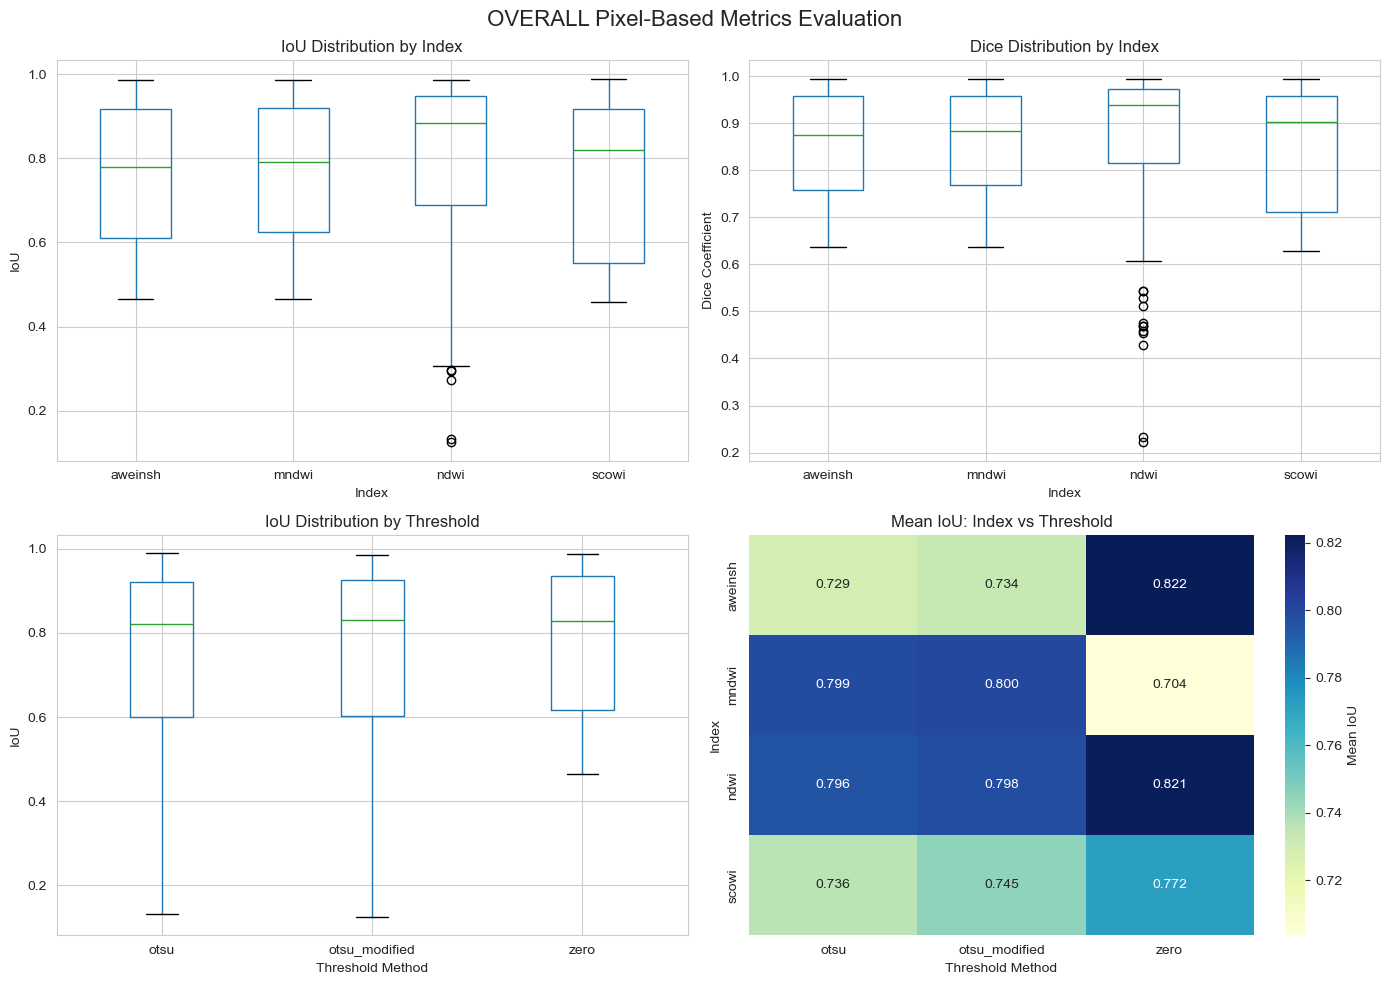

In [20]:
# Set style
sns.set_style("whitegrid")

for study_name in STUDY_NAMES + ["Overall"]:

    if study_name != "Overall":
        results_df_to_plot = results_df[results_df['study_name'] == study_name]
    else:
        results_df_to_plot = results_df.copy()

    # Create figure with subplots
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Plot 1: IoU by Index
    ax1 = axes[0, 0]
    results_df_to_plot.boxplot(column='iou', by='index', ax=ax1)
    ax1.set_title('IoU Distribution by Index')
    ax1.set_xlabel('Index')
    ax1.set_ylabel('IoU')
    ax1.get_figure().suptitle('')  # Remove default title

    # Plot 2: Dice by Index
    ax2 = axes[0, 1]
    results_df_to_plot.boxplot(column='dice', by='index', ax=ax2)
    ax2.set_title('Dice Distribution by Index')
    ax2.set_xlabel('Index')
    ax2.set_ylabel('Dice Coefficient')
    ax2.get_figure().suptitle('')

    # Plot 3: IoU by Threshold
    ax3 = axes[1, 0]
    results_df_to_plot.boxplot(column='iou', by='threshold', ax=ax3)
    ax3.set_title('IoU Distribution by Threshold')
    ax3.set_xlabel('Threshold Method')
    ax3.set_ylabel('IoU')
    ax3.get_figure().suptitle('')

    # Plot 4: Mean IoU Heatmap (Index vs Threshold)
    ax4 = axes[1, 1]
    pivot_table = results_df_to_plot.pivot_table(values='iou', index='index', columns='threshold', aggfunc='mean')
    sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax4, cbar_kws={'label': 'Mean IoU'})
    ax4.set_title('Mean IoU: Index vs Threshold')
    ax4.set_xlabel('Threshold Method')
    ax4.set_ylabel('Index')

    fig.suptitle(f'{study_name.upper()} Pixel-Based Metrics Evaluation', fontsize=16)
    plt.tight_layout()

    # Save figure
    output_fig_path = Path("..") / "results" / f"evaluation_overview_{study_name.lower()}.png"
    plt.savefig(output_fig_path, dpi=300, bbox_inches='tight')
    print(f"\nFigure saved to: {output_fig_path}")

    plt.show()

Visualizing boundary zone for a sample patch...
Sample: salinas - 2023-08-22 - scowi - otsu_modified - Patch 1


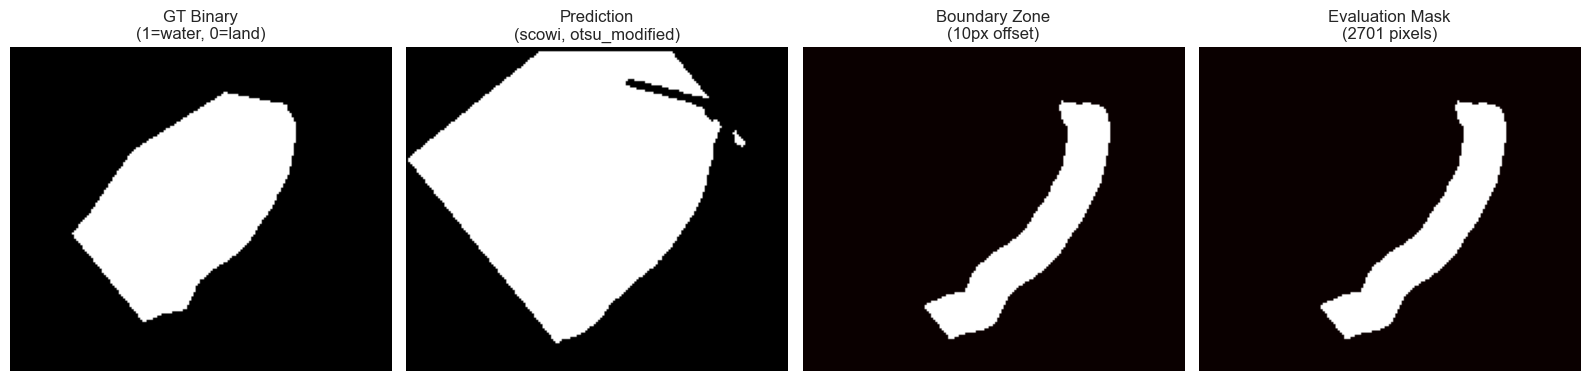


Boundary zone visualization complete!
Boundary pixels: 2701
IoU: 0.489
Dice: 0.656


In [17]:
# Visualize boundary zone for a sample patch
if len(results_df) > 0:
    print("Visualizing boundary zone for a sample patch...")
    
    # Get a sample result
    sample = results_df.iloc[-1]
    print(f"Sample: {sample['study_name']} - {sample['date']} - {sample['index']} - {sample['threshold']} - Patch {sample['patch_id']}")
    
    # Reconstruct paths
    gt_filename = f"{sample['date'].replace('-', '-')}-{sample['time'].replace(':', '-')}_S2_{sample['tile']}_{sample['site']}_mask_gt.tif"
    gt_path = IMAGES_DIR / sample['study_name'] / "annotation_masks_gt" / gt_filename
    
    binary_mask_path = get_binary_mask_path(
        gt_filename, 
        sample['study_name'], 
        sample['index'], 
        sample['threshold']
    )
    
    # Load patches
    patches_path = PATCHES_DIR / sample['study_name'] / f"roi_{sample['study_name']}_{PATCH_SIZE}_patches.shp"
    try:
        patches_gdf = gpd.read_file(patches_path, engine='fiona')
    except:
        import fiona
        fiona.drvsupport.supported_drivers['ESRI Shapefile'] = 'rw'
        with fiona.open(patches_path) as src:
            geometries = []
            for feature in src:
                from shapely.geometry import shape
                geometries.append(shape(feature['geometry']))
        patches_gdf = gpd.GeoDataFrame({'geometry': geometries})
    
    # Get the specific patch
    patch_geom = patches_gdf.iloc[sample['patch_id']].geometry
    
    # Crop GT and prediction
    gt_cropped, _, _ = crop_raster_by_geometry(gt_path, patch_geom, nodata=None)
    pred_cropped, _, _ = crop_raster_by_geometry(binary_mask_path, patch_geom, nodata=0)
    
    # Collapse GT to binary
    gt_binary, ignore_mask = collapse_gt_to_binary(
        gt_cropped,
        water_classes=GT_CLASS_MAPPING['water_classes'],
        no_water_classes=GT_CLASS_MAPPING['no_water_classes'],
        ignore_classes=GT_CLASS_MAPPING['ignore_classes']
    )
    
    # Create boundary zone (now with ignore_mask parameter)
    boundary_zone = create_boundary_zone_mask(gt_binary, ignore_mask, BOUNDARY_OFFSET_PIXELS)
    evaluation_mask = boundary_zone & (~ignore_mask)
    
    # Plot
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    axes[0].imshow(gt_binary, cmap='gray')
    axes[0].set_title('GT Binary\n(1=water, 0=land)')
    axes[0].axis('off')
    
    axes[1].imshow(pred_cropped, cmap='gray')
    axes[1].set_title(f'Prediction\n({sample["index"]}, {sample["threshold"]})')
    axes[1].axis('off')
    
    axes[2].imshow(boundary_zone, cmap='hot')
    axes[2].set_title(f'Boundary Zone\n({BOUNDARY_OFFSET_PIXELS}px offset)')
    axes[2].axis('off')
    
    axes[3].imshow(evaluation_mask, cmap='hot')
    axes[3].set_title(f'Evaluation Mask\n({sample["boundary_pixel_count"]} pixels)')
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nBoundary zone visualization complete!")
    print(f"Boundary pixels: {sample['boundary_pixel_count']}")
    print(f"IoU: {sample['iou']:.3f}")
    print(f"Dice: {sample['dice']:.3f}")
else:
    print("No results available for visualization.")

In [16]:
sample

study_name                    puntal
date                      2016-06-26
time                        11:12:58
tile                           30TVP
site                          PUNTAL
patch_id                           0
index                           ndwi
threshold                       zero
iou                         0.936324
dice                        0.967115
boundary_pixel_count            2353
boundary_offset_pixels            10
Name: 0, dtype: object